## Análisis de datos II - Clase 8
---

### Auditoría de sesgo
---


En esta notebook vamos a simular un escenario de aprobación de créditos bancarios. Vamos a crear un modelo intencionalmente sesgado, vamos a medir su disparidad usando métricas de equidad tradicionales, y finalmente vamos a utilizar SHAP:
- para comprender cómo el modelo toma sus decisiones.
- para evaluar si esas decisiones presentan disparidades entre distintos grupos definidos por un atributo sensible o protegido (en este caso, el género).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score

### Generación de un dataset sintético (con sesgo)

Creamos un dataset donde la variable protegida sea el Género (genero: 0 = Grupo Minoritario/Mujeres, 1 = Grupo Mayoritario/Hombres).

Simulamos que el modelo aprende un sesgo donde a las personas del género 0 se les castiga más el puntaje crediticio.

In [2]:
np.random.seed(42)
n_muestras = 5000

# Variables simuladas
genero = np.random.binomial(1, 0.5, n_muestras) # 0 = Grupo minoritario, 1 = Grupo mayoritario
edad = np.random.randint(18, 70, n_muestras)
ingresos = np.random.normal(50000, 15000, n_muestras)
historial_crediticio = np.random.randint(0, 10, n_muestras)

# Inyectamos sesgo intencional. El género 0 recibe una penalización artificial fuerte en su puntaje
puntaje_base = (ingresos / 1000) * 0.5 + historial_crediticio * 2.5 - (edad * 0.03)
penalizacion_sesgo = np.where(genero == 0, 12, 0) # Aumentamos el castigo al grupo 0
puntaje_final = puntaje_base - penalizacion_sesgo + np.random.normal(0, 2, n_muestras)

# Ponemos un umbral fijo en la variable target para que la tasa de aprobación difiera claramente por grupo
umbral = 35  # Umbral fijo
# umbral = np.median(puntaje_final) otra opción
aprobado = (puntaje_final > umbral).astype(int)

# Creamos el dataframe
df = pd.DataFrame({
    'edad': edad,
    'ingresos': ingresos,
    'historial_crediticio': historial_crediticio,
    'genero': genero, # Variable protegida
    'aprobado': aprobado
})

print("Distribución del dataset:")
print(df['aprobado'].value_counts())

Distribución del dataset:
aprobado
0    3486
1    1514
Name: count, dtype: int64


In [3]:
df.head()

,edad,ingresos,historial_crediticio,genero,aprobado
0,68,49800.007294,7,0,0
1,57,44859.401696,4,1,0
2,24,41005.045185,5,1,0
3,49,20539.517630,7,1,0
4,65,24006.895225,1,0,0


Antes de entrenar el modelo, observemos cómo quedó construido el dataset. La siguiente figura muestra que el porcentaje de aprobaciones ya difere entre ambos géneros debido al sesgo histórico que introdujimos.

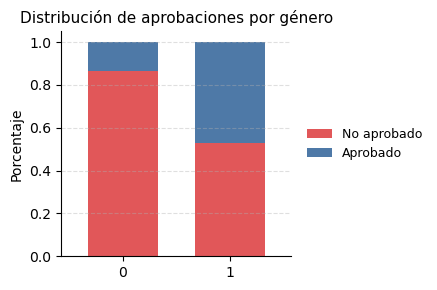

In [4]:
fig, ax = plt.subplots(figsize=(4.5, 3))

tabla = pd.crosstab(
    df["genero"],
    df["aprobado"],
    normalize="index"   # porcentajes por fila (por género)
)
tabla.columns = ["No aprobado", "Aprobado"]

tabla.plot(
    kind="bar",
    stacked=True,
    color=["#E15759", "#4E79A7"],
    width=0.65,
    ax=ax
)

ax.set_title("Distribución de aprobaciones por género", fontsize=11)
ax.set_xlabel("")
ax.set_ylabel("Porcentaje")
ax.tick_params(axis="x", rotation=0)

# Leyenda afuera
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=9
)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

In [5]:
print(tabla)

        No aprobado  Aprobado
genero                       
0            0.8660    0.1340
1            0.5284    0.4716


El sesgo está presente en los datos, no fue generado todavía por el modelo.

---
### Entrenamiento del modelo (Random Forest)

Ahora entrenaremos un modelo utilizando estos datos para ver si aprende ese patrón histórico.

Entrenamos un modelo de ML con todas las variables (incluyendo el género o permitiendo que el modelo aprenda proxies si se omitiera; aquí lo incluimos para ver su impacto directo).

In [6]:
X = df[['edad', 'ingresos', 'historial_crediticio', 'genero']]
y = df['aprobado']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenamos un Random Forest
modelo = RandomForestClassifier(
    n_estimators=1000,
    max_depth=None,
    min_samples_split=2,
    random_state=0
)

modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

### Métricas del modelo base

In [7]:
# Evaluamos el rendimiento general
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.97      0.97       724
           1       0.93      0.89      0.91       276

    accuracy                           0.95      1000
   macro avg       0.94      0.93      0.94      1000
weighted avg       0.95      0.95      0.95      1000



### Auditoría con SHAP
Antes de medir si el modelo es justo, primero entendamos cómo está tomando sus decisiones. SHAP nos permitirá identificar qué variables impulsan las predicciones y detectar si alguna variable sensible (o un proxy de ella) está influyendo.

In [8]:
# Inicializamos el explainer de SHAP para árboles
explainer = shap.TreeExplainer(modelo)
explanation = explainer(X_test)

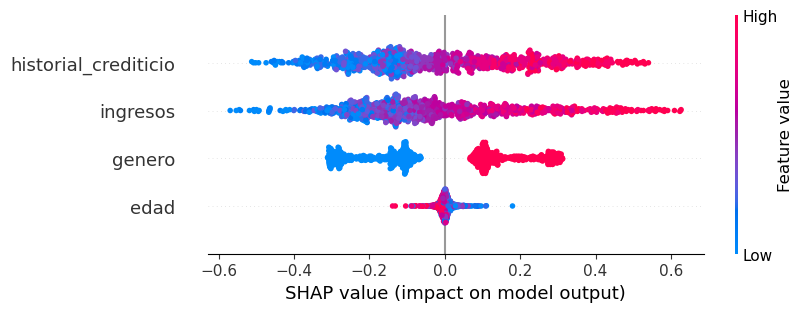

In [9]:
# Gráfico resumen
shap.plots.beeswarm(explanation[:, :, 1])

**Algunos insights**
- ingresos es la variable con mayor impacto
- historial_crediticio también influye fuertemente
- género aparece entre las variables importantes

#### Definimos el atributo sensible

Aunque el género tenga baja importancia directa, puede influir indirectamente a través de variables correlacionadas. Por eso analizamos las explicaciones separadas por grupo

1) Segmentamos por grupo protegido: dividimos los datos en función de la variable protegida género.

In [10]:
A_train = X_train["genero"]
A_test = X_test["genero"]

# Identifica el índice de la columna "genero" para poder excluirla de los beeswarm plots
feature_names = list(X_test.columns)
idx_genero = feature_names.index("genero")

2) Explicamos focalizados en la clase positiva, de manera separada para cada valor de genero.

Buscamos ver qué factores impulsan la aprobación de un crédito de manera independiente para cada género.

In [11]:
# Explicación de la clase positiva
exp1 = explanation[:, :, 1]
mask0 = (X_test["genero"] == 0).to_numpy() # para género 0 (Grupo minoritario)
mask1 = (X_test["genero"] == 1).to_numpy() # para género 1 (Grupo mayoritario)

# Filtrar las explicaciones: sacamos la columna de género usando una máscara de índices
features_a_mostrar = [i for i, name in enumerate(feature_names) if name != "genero"]
exp1_sin_genero = exp1[:, features_a_mostrar]

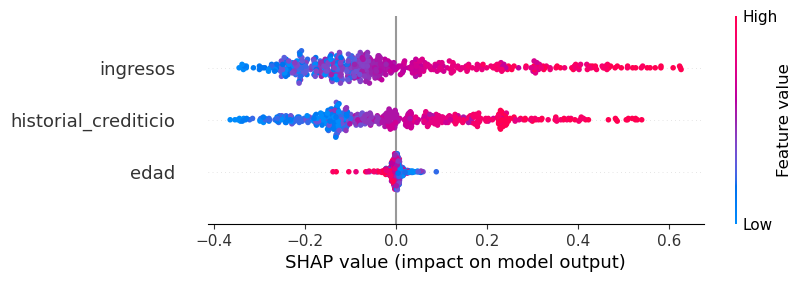

In [12]:
shap.plots.beeswarm(exp1_sin_genero[mask0]) # mujeres

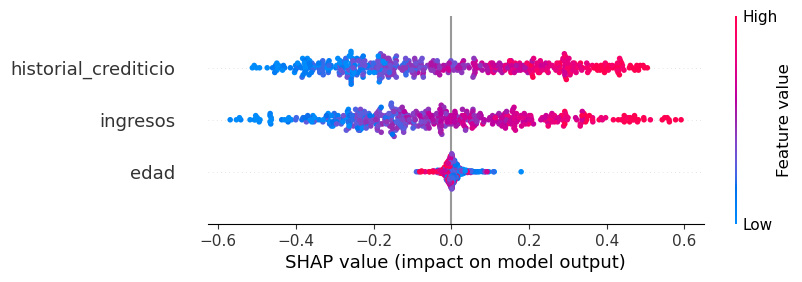

In [13]:
shap.plots.beeswarm(exp1_sin_genero[mask1]) # hombres

In [14]:
compara_x_grupo = pd.DataFrame({
    "Grupo 0": np.abs(exp1[mask0].values).mean(axis=0),
    "Grupo 1": np.abs(exp1[mask1].values).mean(axis=0),
}, index=X.columns)

compara_x_grupo

,Grupo 0,Grupo 1
edad,0.010681,0.014959
ingresos,0.169080,0.202446
historial_crediticio,0.155391,0.229368
genero,0.183820,0.167975


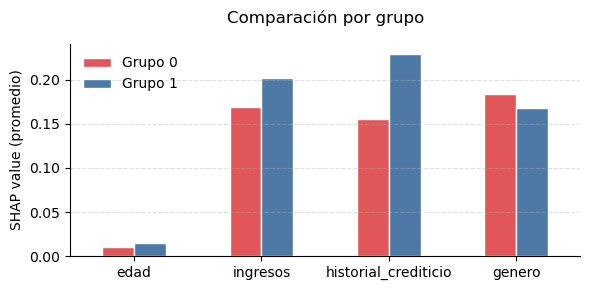

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))

compara_x_grupo.plot(
    kind="bar", color=["#E15759", "#4E79A7"],
    edgecolor="white", ax=ax)

ax.set_title("Comparación por grupo", fontsize=12, pad=15)
ax.set_xlabel("")
ax.set_ylabel("SHAP value (promedio)", fontsize=10)
ax.legend(title="", frameon=False)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**¿el modelo premia o castiga variables como los ingresos o el historial_crediticio *con distinta intensidad* dependiendo del género del solicitante?**

La respuesta es SÍ. Si bien en ambos casos, tener buenos ingresos y un historial crediticio favorable impulsan la clase positiva, hay una asimetría en la magnitud del impacto:
- Ingresos: En el grupo minoritario (mujeres), ingresos altos generan impulsos positivos superiores (valores SHAP > 0.6) en comparación con el grupo mayoritario.
- Historial crediticio: En el grupo mayoritario (hombres), tener un mal historial crediticio genera penalizaciones negativas más severas.

**Conclusión**

El modelo está usando activamente la variable género para asignar la predicción (por ejemplo, para denegar o aprobar un crédito). Hay dos lecturas posibles:

1. Discriminación directa: El modelo aprendió a penalizar o beneficiar a las personas simplemente por pertenecer al Grupo 0 o al Grupo 1, dándole a la variable genero un peso propio de casi el $18\%$.

2. Efecto Proxy: A veces, el género absorbe sesgos históricos del mercado laboral (por ejemplo, brechas salariales históricas). El modelo usa el género para "compensar" esa falta de información.

---
### Métricas de equidad

La importancia de SHAP no demuestra por sí sola la existencia de un sesgo. Para afirmar que el modelo trata de manera desigual a distintos grupos es necesario complementarlo con métricas de equidad.

Primero, veamos algunas métricas de desempeño. Si son muy distintas entre grupos, podría existir un problema de equidad.

In [16]:
results = []

for g in sorted(A_test.unique()):
    mask = A_test == g

    results.append({
        "grupo": g,
        "accuracy": accuracy_score(y_test[mask], y_pred[mask]),
        "precision": precision_score(y_test[mask], y_pred[mask]),
        "recall": recall_score(y_test[mask], y_pred[mask]),
        "selection_rate": y_pred[mask].mean()
    })

mf = pd.DataFrame(results).set_index("grupo")
mf

,accuracy,precision,recall,selection_rate
grupo,,,,
0,0.958095,0.915254,0.760563,0.112381
1,0.943158,0.927885,0.941463,0.437895


Es bastante evidente que hay diferencia entre los grupos. Calculemos ahora algunas métricas de equidad.

#### Demographic Parity (Paridad Demográfica)

Evaluemos el Demographic Parity (Paridad Demográfica): ¿Qué porcentaje de cada grupo recibe una predicción positiva (crédito aprobado)?

Todos los grupos deberían recibir la misma proporción de predicciones positivas.

In [17]:
# Unimos test con las predicciones
df_test = X_test.copy()
df_test['prediccion'] = y_pred

# Calculamos tasa de aprobación por género
tasa_aprobacion = df_test.groupby('genero')['prediccion'].mean()

print("Demographic Parity:")
print(f"\nGrupo protegido - Grupo de referencia = {tasa_aprobacion[1]:.4f} - {tasa_aprobacion[0]:.4f} = {tasa_aprobacion[1] - tasa_aprobacion[0]:.4f}")

Demographic Parity:

Grupo protegido - Grupo de referencia = 0.4379 - 0.1124 = 0.3255


**Observación**

Este valor indica que la probabilidad de que un integrante del grupo minoritario (mujeres) reciba la aprobación del crédito (y_pred = 1) es de apenas el 32.5% en comparación con el grupo mayoritario (hombres), lo que revela un sesgo desfavorable.

#### Adverse Impact Ratio (AIR)

In [18]:
print("Adverse Impact Ratio (AIR):")
print(f"\nGrupo protegido / Grupo de referencia: {tasa_aprobacion[0] / tasa_aprobacion[1]:.4f}")

Adverse Impact Ratio (AIR):

Grupo protegido / Grupo de referencia: 0.2566


**Observación**

Este valor está muy por debajo del umbral estándar (0.8), lo que confirma la existencia de una disparidad en las decisiones de aprobación entre ambos grupos.

#### Hallazgos

El grupo 1 tiene una tasa de aprobación notablemente superior al grupo 0. Las métricas nos dicen que hay sesgo, pero no el mecanismo exacto.

#### Equalized Odds (Oportunidades ecuánimes)

Mientras que las métricas anteriores se calculan en base a las predicciones finales (cuántos créditos se aprueban por grupo), Equalized Odds (Oportunidades Ecuánimes) evalúa si el modelo es igual de preciso (y comete los mismos errores) para todos los grupos.

Equalized Odds exige tasas similares de verdaderos positivos y falsos positivos.

In [19]:
# Unimos los datos reales (y_test), las predicciones (y_pred) y el género
df_eo = X_test.copy()
df_eo['y_true'] = y_test.values
df_eo['y_pred'] = y_pred

# Función para calcular TPR y FPR por grupo
def calcular_tasas_equidad(df, grupo_col):
    resultados = {}
    for grupo in df[grupo_col].unique():
        subset = df[df[grupo_col] == grupo]
        # Matriz de confusión para el subgrupo
        # tn, fp, fn, tp
        tn, fp, fn, tp = confusion_matrix(subset['y_true'], subset['y_pred']).ravel()
        
        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0 # Tasa de Verdaderos Positivos
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0 # Tasa de Falsos Positivos
        
        resultados[grupo] = {'TPR (Aciertos)': tpr, 'FPR (Errores)': fpr}
        
    return pd.DataFrame(resultados).T

metricas_eo = calcular_tasas_equidad(df_eo, 'genero')
print("Equalized Odds por grupo")
print(metricas_eo)

Equalized Odds por grupo
   TPR (Aciertos)  FPR (Errores)
0        0.760563       0.011013
1        0.941463       0.055556


#### Hallazgos

Para cumplir Equalized Odds, la TPR como la FPR deberían ser iguales en ambos grupos. Si difieren, significa que el modelo no comete los mismos tipos de errores para todos.

La FPR es mucho menor en el Grupo 0 (minoritario). En la práctica, el modelo es más estricto con ese grupo: para evitar equivocarse aprobando malos créditos, termina rechazando más personas que en realidad sí habrían pagado.

### Gráfico de dependencia SHAP por grupo protegido
El Dependence Plot de SHAP permite cruzar una variable con su impacto, segmentando visualmente por el atributo protegido para ver si la regla del modelo cambia según el grupo.

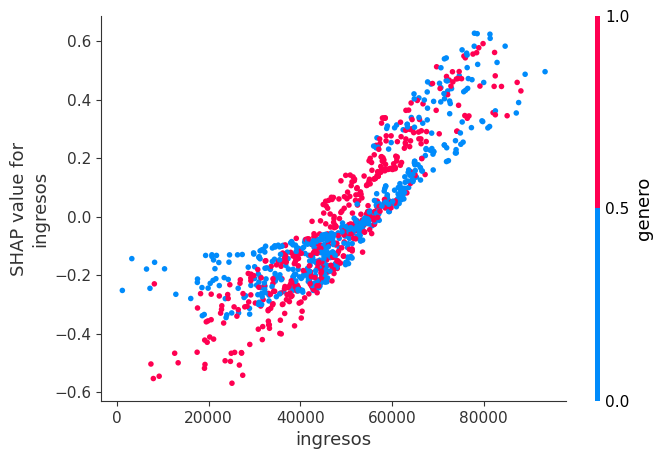

In [20]:
# Analizamos cómo la variable 'ingresos' afecta las decisiones, pintando por 'genero'
shap.dependence_plot("ingresos", explanation[:, :, 1].values, X_test, interaction_index="genero")

#### Interpretación general (tendencia)

Si ignoramos el color y miramos la forma general de la nube de puntos, vemos una clara tendencia ascendente. A medida que aumentan los ingresos (Eje X), también aumenta el valor SHAP (Eje Y).

El modelo, lógicamente, interpreta que a mayores ingresos, mayor es la probabilidad de aprobación (predicción 1 es aprobación).

#### Interpretación del sesgo (interacción con el género)

Al observar la distribución de los colores, el gráfico sugiere que el modelo no trata a hombres y mujeres por igual, incluso cuando tienen los mismos ingresos.

Por ejemplo, para un ingreso de 50.000:
- Los puntos azules (mujeres) tienden a presentar valores SHAP más negativos, cercanos a -0.1.
- Los puntos rojos (hombres) muestran una mayor dispersión (por encima y por debajo de 0).

Esto sugiere que, a igualdad de ingresos, el modelo tiende a reducir más la probabilidad de aprobación para las mujeres que para los hombres.

Visto de otra manera, para que una mujer tenga el mismo impacto positivo en su predicción (el mismo valor SHAP) que un hombre, necesita demostrar un nivel de ingresos más alto. Por ejemplo, una mujer con 60,000 de ingresos tiene un valor SHAP similar a un hombre con 40,000.

### Conclusión
Explicabilidad y equidad (fairness) no compiten: se complementan. Las métricas de equidad pueden indicar que existe una disparidad entre grupos, mientras que SHAP puede darnos pistas sobre qué variables están contribuyendo a esa disparidad y ayudarnos a formular hipótesis sobre su origen.